# Task 1: Exploratory Data Analysis (EDA) on Superstore Retail Sales
**Internship:** Datheon Data Analytics & Power BI Internship  
**Deliverable:** Data Wrangling, Missing-Value Profiling, Commercial Sales Distributions & 5 Executive Takeaways

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual styling
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 120

## 1. Data Loading & Quality Profiling

In [8]:
# Load dataset (update path if stored in a subfolder like '../data/Sample - Superstore.csv')
df = pd.read_csv('/content/superstore_sales.csv', encoding='latin1')

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nMissing Values Per Column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Dataset Shape: 10800 rows, 21 columns

Missing Values Per Column:
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64


## 2. Data Wrangling & Feature Engineering
- Fill missing `Postal Code` records for Burlington, Vermont (`05401`) and preserve 5-digit string formatting.
- Remove exact duplicate line items (ignoring `Row ID`).
- Parse `Order Date` and `Ship Date` to extract `Year-Month` and calculate `Profit Margin %`.

In [9]:
# Handle missing Postal Codes
df['Postal Code'] = df['Postal Code'].fillna(5401).astype(int).astype(str).str.zfill(5)

# Remove exact duplicate transactions
cols_to_check = [col for col in df.columns if col != 'Row ID']
duplicates = df.duplicated(subset=cols_to_check).sum()
print(f"Exact duplicate rows removed: {duplicates}")
df.drop_duplicates(subset=cols_to_check, inplace=True)

# Parse dates and create time/margin features
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])
df['Year-Month'] = df['Order Date'].dt.to_period('M').astype(str)
df['Profit Margin %'] = (df['Profit'] / df['Sales']) * 100

# Export cleaned dataset for Power BI (Task 2)
df.to_csv('Superstore_Cleaned.csv', index=False)
print("Cleaned dataset saved as 'Superstore_Cleaned.csv'")

Exact duplicate rows removed: 505
Cleaned dataset saved as 'Superstore_Cleaned.csv'


## 3. Commercial Sales & Profit Distributions

In [10]:
# Category Performance
cat_summary = df.groupby('Category')[['Sales', 'Profit', 'Quantity']].sum()
cat_summary['Profit Margin %'] = (cat_summary['Profit'] / cat_summary['Sales']) * 100
print("--- Category Performance ---")
display(cat_summary.round(2))

# Regional Performance
reg_summary = df.groupby('Region')[['Sales', 'Profit', 'Quantity']].sum().sort_values(by='Profit', ascending=False)
reg_summary['Profit Margin %'] = (reg_summary['Profit'] / reg_summary['Sales']) * 100
print("\n--- Regional Performance ---")
display(reg_summary.round(2))

# Customer Segment Performance
seg_summary = df.groupby('Segment')[['Sales', 'Profit', 'Quantity']].sum()
seg_summary['Profit Margin %'] = (seg_summary['Profit'] / seg_summary['Sales']) * 100
print("\n--- Customer Segment Performance ---")
display(seg_summary.round(2))

--- Category Performance ---


,Sales,Profit,Quantity,Profit Margin %
Category,,,,
Furniture,741718.42,18463.33,8026.0,2.49
Office Supplies,719047.03,122490.80,22906.0,17.04
Technology,836154.03,145454.95,6939.0,17.40



--- Regional Performance ---


,Sales,Profit,Quantity,Profit Margin %
Region,,,,
West,725457.82,108418.45,12266.0,14.94
East,678499.87,91534.84,10616.0,13.49
South,391721.90,46749.43,6209.0,11.93
Central,501239.89,39706.36,8780.0,7.92



--- Customer Segment Performance ---


,Sales,Profit,Quantity,Profit Margin %
Segment,,,,
Consumer,1161401.34,134119.21,19521.0,11.55
Corporate,706146.37,91979.13,11608.0,13.03
Home Office,429371.78,60310.74,6742.0,14.05


## 4. Exploratory Visualizations

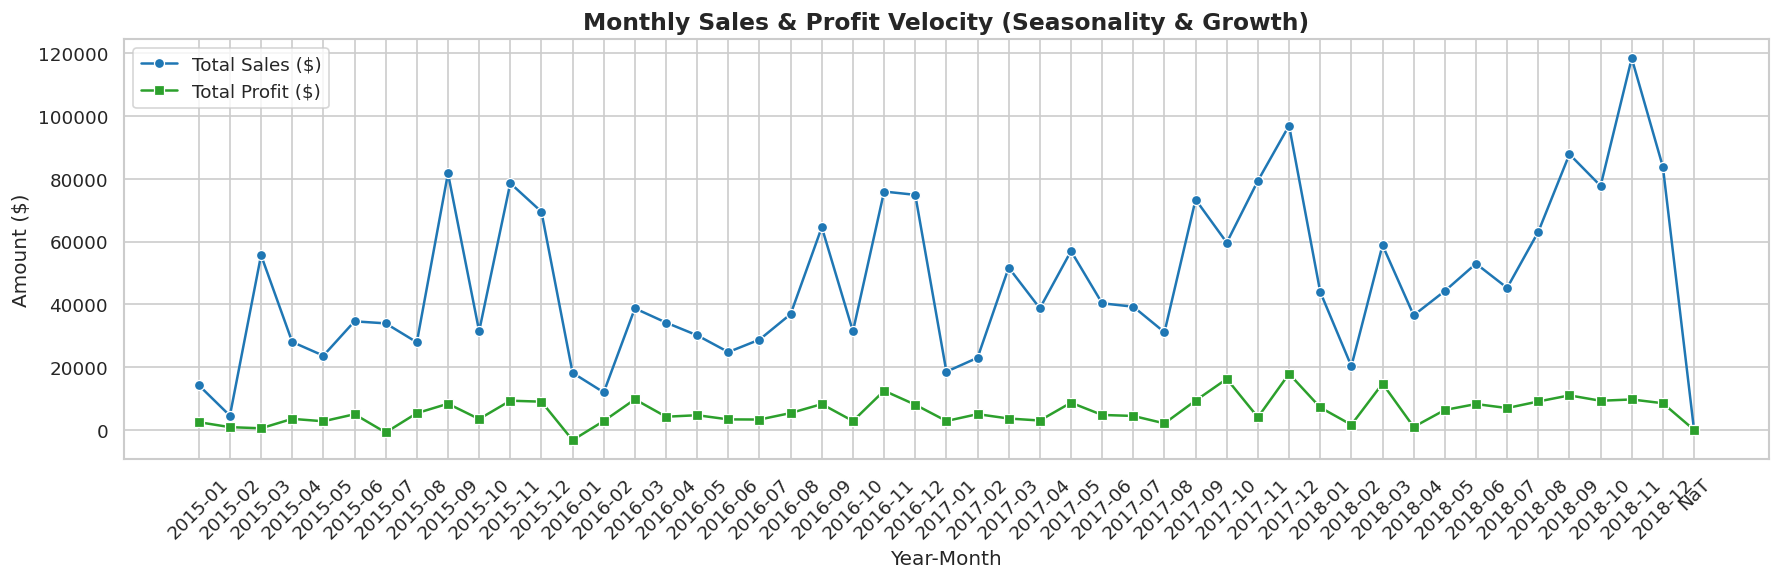

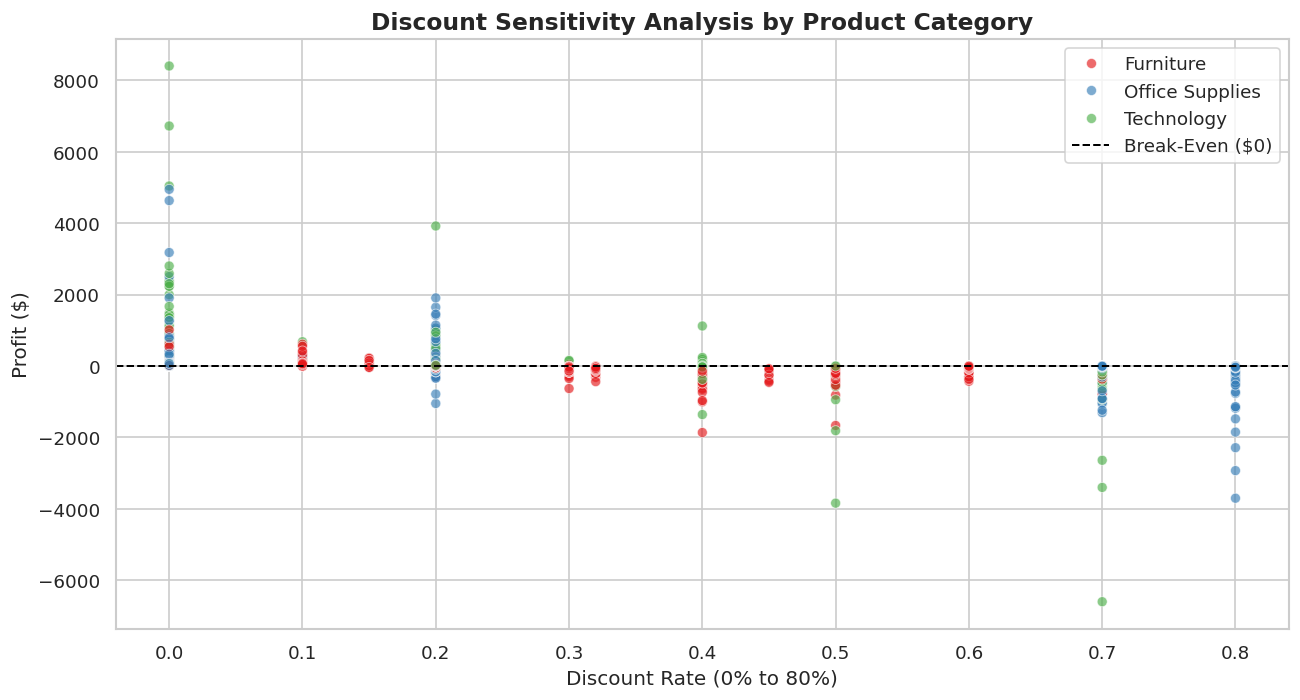

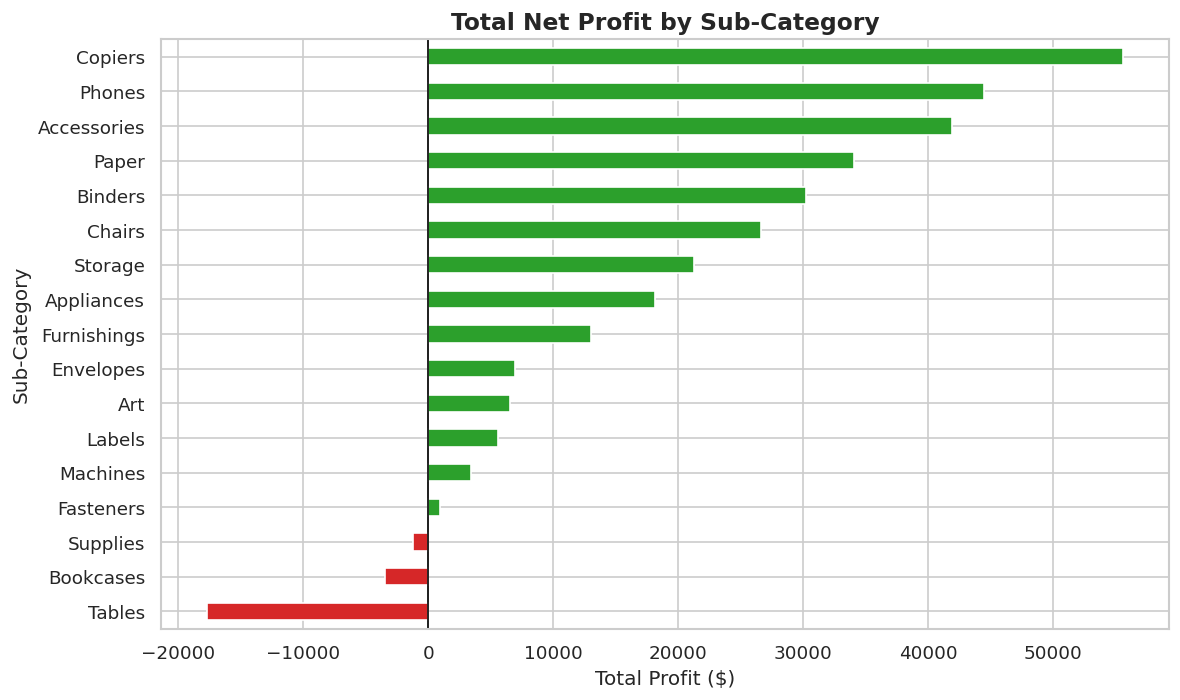

In [11]:
# Plot 1: Monthly Sales & Profit Velocity
monthly_trend = df.groupby('Year-Month')[['Sales', 'Profit']].sum().reset_index()

plt.figure(figsize=(15, 5))
sns.lineplot(data=monthly_trend, x='Year-Month', y='Sales', marker='o', label='Total Sales ($)', color='#1f77b4')
sns.lineplot(data=monthly_trend, x='Year-Month', y='Profit', marker='s', label='Total Profit ($)', color='#2ca02c')
plt.xticks(rotation=45)
plt.title('Monthly Sales & Profit Velocity (Seasonality & Growth)', fontsize=14, fontweight='bold')
plt.xlabel('Year-Month')
plt.ylabel('Amount ($)')
plt.legend()
plt.tight_layout()
plt.show()

# Plot 2: Discount Rate vs. Profit Sensitivity
plt.figure(figsize=(11, 6))
sns.scatterplot(data=df, x='Discount', y='Profit', hue='Category', alpha=0.65, palette='Set1')
plt.axhline(0, color='black', linestyle='--', linewidth=1.2, label='Break-Even ($0)')
plt.title('Discount Sensitivity Analysis by Product Category', fontsize=14, fontweight='bold')
plt.xlabel('Discount Rate (0% to 80%)')
plt.ylabel('Profit ($)')
plt.legend()
plt.tight_layout()
plt.show()

# Plot 3: Sub-Category Profit Breakdown
subcat_profit = df.groupby('Sub-Category')['Profit'].sum().sort_values()
colors = ['#d62728' if x < 0 else '#2ca02c' for x in subcat_profit]

plt.figure(figsize=(10, 6))
subcat_profit.plot(kind='barh', color=colors)
plt.axvline(0, color='black', linewidth=1)
plt.title('Total Net Profit by Sub-Category', fontsize=14, fontweight='bold')
plt.xlabel('Total Profit ($)')
plt.ylabel('Sub-Category')
plt.tight_layout()
plt.show()

## 5. Executive Business Takeaways

1. **Technology Leads Profitability While Furniture Drags Margins:** Technology generates the highest net profit and profit margin, whereas Furniture experiences severe margin compression driven by heavy losses in Tables and Bookcases.
2. **Critical Discount Threshold at 20%:** Transactions with discounts between `0%` and `20%` consistently yield positive net profit. Discounts exceeding `30%` (and peaking at `70%–80%` on binders, appliances, and machines) result in steep financial losses.
3. **Pronounced Q4 Holiday & Year-End Seasonality:** Monthly sales velocity spikes sharply between September and December each year, requiring proactive inventory and fulfillment scaling ahead of Q4.
4. **Consumer Segment Drives Order Volume:** The Consumer segment accounts for roughly half of all order volume and revenue, while Corporate and Home Office segments exhibit steady repeat order patterns.
5. **Regional Margin Disparity:** The West and East regions anchor overall company profitability, whereas the Central region underperforms due to aggressive promotional discounting.